In [84]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification

In [85]:
X,y = make_classification(n_features=5, n_redundant=0, n_informative=5,n_clusters_per_class=1)

In [86]:
df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()

(100, 6)


,col1,col2,col3,col4,col5,target
0,-0.994236,-1.235010,2.065022,0.208893,-2.433714,0
1,0.380307,0.479159,-1.806488,-0.619796,0.278814,1
2,-2.045723,-1.470159,-0.998039,-1.854482,0.677436,1
3,-1.266511,-1.810186,-1.790010,-4.214912,1.179867,1
4,-1.343820,-0.786805,-0.711744,-0.369093,0.777148,0


In [87]:
# function for row sampling

def sample_rows(df,percent):
  return df.sample(int(percent*df.shape[0]),replace=True)

In [88]:
# function for feature sampling
import random
def sample_features(df,percent):
  cols = df.columns.tolist()[:-1]
  cols = random.sample(cols,int(percent*(df.shape[1]-1)))
  new_df = df[cols]
  new_df['target'] = df['target']
  return new_df

In [89]:
# function for combined sampling

def combined_sampling(df,row_percent,col_percent):
  new_df = sample_rows(df,row_percent)
  return sample_features(new_df,col_percent)

In [90]:

df1 = combined_sampling(df,0.5,0.5)

C:\Users\bilal\AppData\Local\Temp\ipykernel_20492\420131809.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [91]:
df2 = combined_sampling(df,0.5,0.5)

C:\Users\bilal\AppData\Local\Temp\ipykernel_20492\420131809.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [92]:
df3 = combined_sampling(df,0.5,0.5)

C:\Users\bilal\AppData\Local\Temp\ipykernel_20492\420131809.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [93]:
print(df1.columns)
print(df2.columns)
print(df3.columns)

Index(['col5', 'col3', 'target'], dtype='object')
Index(['col4', 'col1', 'target'], dtype='object')
Index(['col5', 'col4', 'target'], dtype='object')


In [94]:
df3

,col5,col4,target
55,-1.010736,1.044267,0
82,-0.721342,0.486689,0
57,1.533003,-1.163176,1
50,-4.556086,-0.999452,0
55,-1.010736,1.044267,0
82,-0.721342,0.486689,0
80,1.359803,-0.934950,1
86,1.938667,0.927649,1
19,-0.797157,1.079756,0
54,1.614874,2.230646,0


In [95]:
from sklearn.tree import DecisionTreeClassifier
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [96]:
clf1.fit(df1.iloc[:,0:2],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:2],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:2],df3.iloc[:,-1])

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [97]:
from sklearn.tree import plot_tree

[Text(0.375, 0.9, 'x[0] <= -0.125\ngini = 0.487\nsamples = 50\nvalue = [21.0, 29.0]'),
 Text(0.25, 0.7, 'gini = 0.0\nsamples = 11\nvalue = [11, 0]'),
 Text(0.3125, 0.8, 'True  '),
 Text(0.5, 0.7, 'x[1] <= 0.722\ngini = 0.381\nsamples = 39\nvalue = [10, 29]'),
 Text(0.4375, 0.8, '  False'),
 Text(0.25, 0.5, 'x[1] <= -0.946\ngini = 0.225\nsamples = 31\nvalue = [4, 27]'),
 Text(0.125, 0.3, 'gini = 0.0\nsamples = 18\nvalue = [0, 18]'),
 Text(0.375, 0.3, 'x[0] <= 0.967\ngini = 0.426\nsamples = 13\nvalue = [4, 9]'),
 Text(0.25, 0.1, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.5, 0.1, 'gini = 0.0\nsamples = 9\nvalue = [0, 9]'),
 Text(0.75, 0.5, 'x[0] <= 2.477\ngini = 0.375\nsamples = 8\nvalue = [6, 2]'),
 Text(0.625, 0.3, 'gini = 0.0\nsamples = 6\nvalue = [6, 0]'),
 Text(0.875, 0.3, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]')]

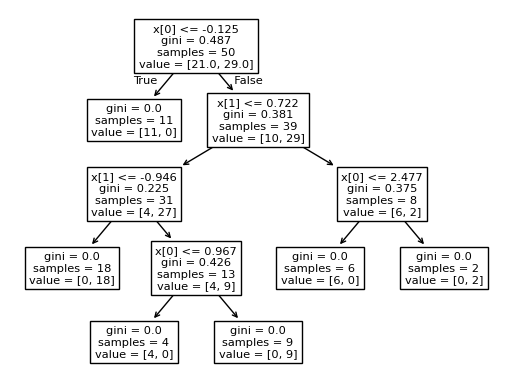

In [98]:
plot_tree(clf1)

[Text(0.5, 0.9166666666666666, 'x[0] <= 0.152\ngini = 0.5\nsamples = 50\nvalue = [25, 25]'),
 Text(0.2, 0.75, 'x[1] <= -0.654\ngini = 0.153\nsamples = 24\nvalue = [2, 22]'),
 Text(0.35, 0.8333333333333333, 'True  '),
 Text(0.1, 0.5833333333333334, 'gini = 0.0\nsamples = 14\nvalue = [0, 14]'),
 Text(0.3, 0.5833333333333334, 'x[1] <= 0.22\ngini = 0.32\nsamples = 10\nvalue = [2, 8]'),
 Text(0.2, 0.4166666666666667, 'x[0] <= -2.09\ngini = 0.444\nsamples = 3\nvalue = [2, 1]'),
 Text(0.1, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.3, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.4, 0.4166666666666667, 'gini = 0.0\nsamples = 7\nvalue = [0, 7]'),
 Text(0.8, 0.75, 'x[1] <= -1.264\ngini = 0.204\nsamples = 26\nvalue = [23, 3]'),
 Text(0.65, 0.8333333333333333, '  False'),
 Text(0.7, 0.5833333333333334, 'x[1] <= -1.378\ngini = 0.375\nsamples = 12\nvalue = [9, 3]'),
 Text(0.6, 0.4166666666666667, 'x[1] <= -1.668\ngini = 0.18\nsamples = 10\nvalue = [9, 1]'),
 Text(0.5, 0.2

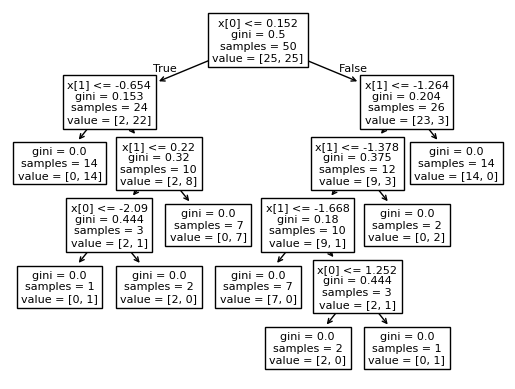

In [99]:
plot_tree(clf2)

[Text(0.4090909090909091, 0.9, 'x[0] <= 0.143\ngini = 0.493\nsamples = 50\nvalue = [28.0, 22.0]'),
 Text(0.18181818181818182, 0.7, 'x[1] <= -2.702\ngini = 0.074\nsamples = 26\nvalue = [25, 1]'),
 Text(0.29545454545454547, 0.8, 'True  '),
 Text(0.09090909090909091, 0.5, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.2727272727272727, 0.5, 'gini = 0.0\nsamples = 25\nvalue = [25, 0]'),
 Text(0.6363636363636364, 0.7, 'x[1] <= 1.822\ngini = 0.219\nsamples = 24\nvalue = [3, 21]'),
 Text(0.5227272727272727, 0.8, '  False'),
 Text(0.45454545454545453, 0.5, 'x[0] <= 0.847\ngini = 0.091\nsamples = 21\nvalue = [1, 20]'),
 Text(0.36363636363636365, 0.3, 'x[1] <= -0.488\ngini = 0.32\nsamples = 5\nvalue = [1, 4]'),
 Text(0.2727272727272727, 0.1, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.45454545454545453, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.5454545454545454, 0.3, 'gini = 0.0\nsamples = 16\nvalue = [0, 16]'),
 Text(0.8181818181818182, 0.5, 'x[0] <= 2.756\ngini = 0.

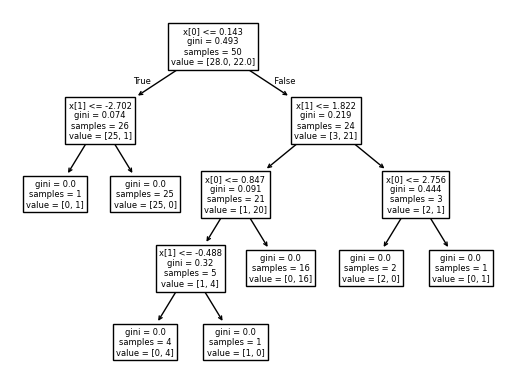

In [100]:
plot_tree(clf3)

In [101]:
clf1.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [102]:
clf2.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [103]:
clf3.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [104]:
df.sample(14,replace=True)

,col1,col2,col3,col4,col5,target
84,-1.327962,-0.729526,-0.990752,-1.214261,0.603111,1
47,0.474845,0.560549,-3.677731,-4.189460,-0.673281,1
14,-1.312674,-0.892592,-1.163711,-1.852172,0.819974,1
48,-0.353555,1.030191,1.949630,-0.981849,-2.047355,0
16,-0.022771,-0.684564,0.967494,-0.331398,-3.324962,0
52,-1.515908,-2.824489,-0.161198,3.075581,0.116060,0
42,-0.784325,-1.075207,-1.338278,-1.593340,0.864463,1
33,-1.723141,-1.156306,1.018361,2.742558,1.183416,0
73,-2.245582,-3.470132,2.307561,3.041962,1.090245,0
49,-0.730784,-1.355581,-1.852372,-2.692967,0.671989,1


In [105]:
# for row sampling 

df4=sample_rows(df,0.5)
df5=sample_rows(df,0.5)
df6=sample_rows(df,0.5)

In [106]:
df3.shape

(50, 3)

In [107]:
clf4= DecisionTreeClassifier()
clf5= DecisionTreeClassifier()
clf6= DecisionTreeClassifier()

In [108]:
clf4.fit(df4.iloc[:,0:5],df4.iloc[:,-1])
clf5.fit(df5.iloc[:,0:5],df5.iloc[:,-1])
clf6.fit(df6.iloc[:,0:5],df6.iloc[:,-1])

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [109]:
from sklearn.tree import plot_tree


[Text(0.4, 0.8333333333333334, 'x[4] <= 0.143\ngini = 0.493\nsamples = 50\nvalue = [28.0, 22.0]'),
 Text(0.2, 0.5, 'gini = 0.0\nsamples = 22\nvalue = [22, 0]'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'x[2] <= 1.763\ngini = 0.337\nsamples = 28\nvalue = [6, 22]'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'gini = 0.0\nsamples = 22\nvalue = [0, 22]'),
 Text(0.8, 0.16666666666666666, 'gini = 0.0\nsamples = 6\nvalue = [6, 0]')]

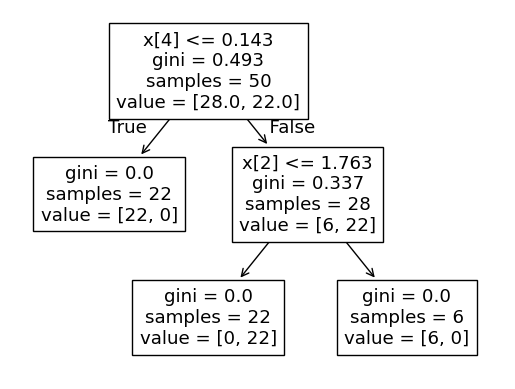

In [110]:
plot_tree(clf4)

[Text(0.5, 0.9, 'x[3] <= 0.064\ngini = 0.487\nsamples = 50\nvalue = [29.0, 21.0]'),
 Text(0.3333333333333333, 0.7, 'x[4] <= -1.904\ngini = 0.346\nsamples = 27\nvalue = [6, 21]'),
 Text(0.41666666666666663, 0.8, 'True  '),
 Text(0.16666666666666666, 0.5, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.5, 0.5, 'x[3] <= -0.47\ngini = 0.219\nsamples = 24\nvalue = [3, 21]'),
 Text(0.3333333333333333, 0.3, 'gini = 0.0\nsamples = 16\nvalue = [0, 16]'),
 Text(0.6666666666666666, 0.3, 'x[4] <= 0.847\ngini = 0.469\nsamples = 8\nvalue = [3, 5]'),
 Text(0.5, 0.1, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.8333333333333334, 0.1, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.6666666666666666, 0.7, 'gini = 0.0\nsamples = 23\nvalue = [23, 0]'),
 Text(0.5833333333333333, 0.8, '  False')]

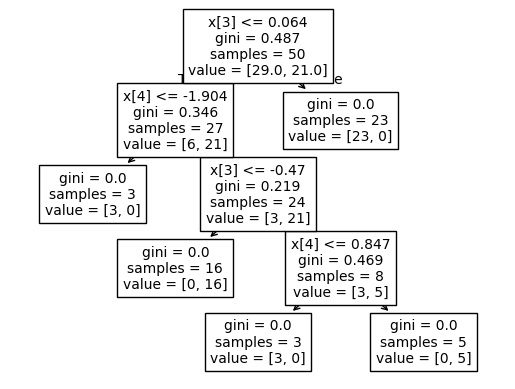

In [111]:
plot_tree(clf5)

[Text(0.375, 0.875, 'x[4] <= -0.125\ngini = 0.497\nsamples = 50\nvalue = [27, 23]'),
 Text(0.25, 0.625, 'gini = 0.0\nsamples = 18\nvalue = [18, 0]'),
 Text(0.3125, 0.75, 'True  '),
 Text(0.5, 0.625, 'x[2] <= 0.912\ngini = 0.404\nsamples = 32\nvalue = [9, 23]'),
 Text(0.4375, 0.75, '  False'),
 Text(0.25, 0.375, 'x[3] <= 2.225\ngini = 0.153\nsamples = 24\nvalue = [2, 22]'),
 Text(0.125, 0.125, 'gini = 0.0\nsamples = 22\nvalue = [0, 22]'),
 Text(0.375, 0.125, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.75, 0.375, 'x[4] <= 3.072\ngini = 0.219\nsamples = 8\nvalue = [7, 1]'),
 Text(0.625, 0.125, 'gini = 0.0\nsamples = 7\nvalue = [7, 0]'),
 Text(0.875, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]')]

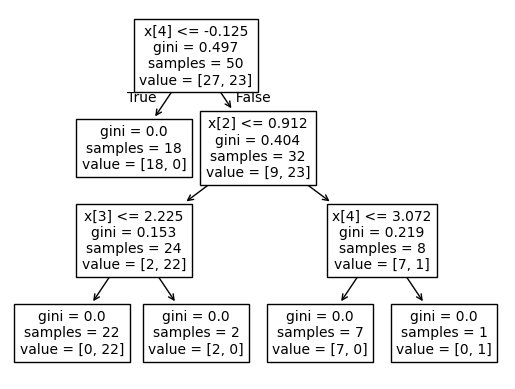

In [112]:
plot_tree(clf6)

In [116]:
clf4.predict(np.array([0.380307,	0.479159,	1.579643,	-0.619796,	0.278814	]).reshape(1,5))

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [117]:
clf5.predict(np.array([0.380307,	0.479159,	1.579643,	-0.619796,	0.278814	]).reshape(1,5))

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [118]:
clf6.predict(np.array([0.380307,	0.479159,	1.579643,	-0.619796,	0.278814	]).reshape(1,5))

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [119]:
# 1,1,0 means majority voting 1 is classified 

In [120]:
# same for column